# 18. Standard evaluation versus pre-onset evaluation: per-minute AUC split at the onset of the decline

Here I measure how much the standard per-minute evaluation inflates predictive skill. The standard protocol labels every minute by whether a fall follows within the next h minutes and computes AUC, so minutes in which the decline is already under way also count as positives, and volatility signals score those minutes high. Following Kamran et al. (2024, NEJM AI), where removing sepsis predictions made after clinicians had already recognized the condition lowered the AUROC from 0.62 to 0.47, I split the positive minutes into pre-onset and in-progress minutes and decompose the AUC exactly. I work with Binance spot BTCUSDT one-minute data over the development period 2023-01 to 2026-04, with crash definitions of 3%, 4% (primary) and 5%.

- I use two labels: the L1 event label (a catalog crash, an x% fall from the high of the previous 240 minutes, arrives 30–240 minutes later; the training label of notebooks 04–17) and the L2 forward-fall label (the price falls by x% or more within the next 240 minutes; common in machine-learning papers).
- As in-progress positives I take, for L1, minutes after the 1% onset of the event that made the minute positive (the endpoint definition of notebooks 12 and 16); for L2 (and L1, secondary), minutes at least x/4 below the high of the previous 240 minutes, which is observable in real time.
- I decompose the standard AUC as (1−π) × AUC(pre-onset positives vs negatives) + π × AUC(in-progress positives vs negatives), where π is the share of in-progress positives. The Kamran-style restricted AUC is the pre-onset term, and the in-progress share of the above-chance AUC is π × (AUC in progress − 0.5) / (standard AUC − 0.5).
- As secondary analyses I also compute the within-regime AUC (only positive–negative pairs in the same 24-hour volatility decile), the calm-start AUC (both classes restricted to minutes not inside a decline), recall at the top 1% and 5% of 2022 scores, and an event study of scores around onset. For uncertainty I draw 500 resamples from a 7-day block bootstrap.
- For L1 I use the models frozen in notebook 16 (M0, the V+F logistic; M3, the GBM). I train the L2 models on 2021 with the same features and settings. M1 (volatility threshold, z_vol) and M2 (VPIN) need no training.

This analysis is exploratory. I reproduce standard practice, while the confirmatory evidence comes from the holdouts of notebooks 11 and 17; I leave the 2018–2020 BTC holdout and the 2018–2019 altcoin holdout out of it. I write the results to `btc_lead_cost_results_77months_spot/standard_protocol_inflation_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

OUT = SPOT_BASE / 'standard_protocol_inflation_v1'; (OUT / 'models').mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
DEFS = {'3pct': 0.03, '4pct': 0.04, '5pct': 0.05}; PRIMARY_DEF = '4pct'
HORIZON = LEAD_MAX
METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
N_BOOT = 500; SEED = 20261101; BLOCK_DAYS = 7; THRESH_Q = (0.99, 0.95); STUDY = (-480, 240)
EVAL_LAST = ts(EVAL_END).value - (HORIZON + 5) * NS

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json']:
    if not _p.is_file():
        raise FileNotFoundError(f'Notebook 16 results are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text())
SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 spec file does not match METHODS_FROZEN.json')
if SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: shared GBM settings differ from notebook 16')

SPEC = {'title': 'Standard per-sample evaluation vs pre-onset-only evaluation (dev 2023-01..2026-04, exploratory)',
        'labels': {'L1_event': 'catalog breach (x% below trailing-240-min peak, 5-min sustain, 24h refractory) 30-240 min after minute t; the notebook 4-17 training label',
                   'L2_forward': 'min close over (t, t+240] <= (1-x) * close_t; the common forward-drawdown label'},
        'in_decline_split': {'event': 'L1 only: t >= 1% onset of the event that makes the label positive (notebooks 12/16 endpoint definition)',
                             'state': 'close_t at least x/4 below the trailing-240-min high (observable at t)'},
        'decomposition': 'AUC_standard = (1-pi)*AUC(pre-onset positives vs negatives) + pi*AUC(in-decline positives vs negatives); '
                         'Kamran-style restricted AUC = AUC(pre-onset positives vs all negatives); '
                         'in-decline share of above-chance AUC = pi*(AUC_in-0.5)/(AUC_standard-0.5)',
        'within_regime': 'AUC over positive-negative pairs in the same 24h realized-volatility decile (deciles over evaluation minutes)',
        'calm_start': 'both classes restricted to minutes less than x/4 below the trailing-240-min high',
        'models': {'L1': 'notebook-16 frozen models (M0 coefficient guard, M3 SHA-256 guard); M1 z_vol and M2 VPIN raw scores',
                   'L2': 'notebook-16 features and settings, trained on 2021 minus the last 245 minutes with the L2 label'},
        'evaluation_minutes': f'{EVAL_START} to {EVAL_END} minus {HORIZON + 5} min, notebook-16 VALID mask',
        'thresholds': f'2022 score quantiles {THRESH_Q}',
        'bootstrap': f'{N_BOOT} resamples of {BLOCK_DAYS}-day blocks, percentile 95% CI, seed {SEED}',
        'event_study': f'score percentile vs the 2022 distribution, minutes {STUDY} around the 1% onset, dev events, L1 models',
        'holdouts': 'not used (BTC 2018-2020 and alt 2018-2019 are locked)',
        'definitions': DEFS, 'gbm_params': GBM_PARAMS, 'features': FEATS, 'notebook16_spec_sha256': FROZEN16['spec_sha256']}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '18_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'18_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/standard_protocol_inflation_v1 | spec sha256 b28949177840d6f7


## 1. Data, features, events and labels

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
CAL = VALID & in_period(T, '2022-01-01', '2023-01-01')
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
SCORED = CAL | (VALID & (T >= ts('2022-01-01').value) & (T < EVAL_LAST))
DD240 = F.dd_240.to_numpy(float)

_c = pd.Series(np.where(np.isfinite(close) & (close > 0), close, np.nan))
FWD_MIN = _c[::-1].rolling(HORIZON, min_periods=1).min()[::-1].shift(-1).to_numpy()
_rng = np.random.default_rng(1); _ix = _rng.choice(np.flatnonzero(EVM), 3000, replace=False)
if not all(np.isclose(FWD_MIN[i], np.nanmin(close[i + 1:i + 1 + HORIZON]), equal_nan=True) for i in _ix):
    raise RuntimeError('GUARD FAIL: forward-minimum construction')

_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1
print(f'evaluation minutes {int(EVM.sum()):,}, {N_WEEKS} blocks of {BLOCK_DAYS} days; features ready in {time.time() - t_:.0f}s')

TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']
E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
CATS = {}
for dname, d in DEFS.items():
    E = price_only_catalog(close, volume, px.index, decline=d)
    for c_ in TCOLS:
        E[c_] = pd.to_datetime(E[c_], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    if dname == '4pct' and (len(E) != len(E_ref) or any(not np.array_equal(E[c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS)):
        raise RuntimeError('GUARD FAIL: 4% catalog differs from the notebook-2 catalog')
    CATS[dname] = E


def labels_for(dname):
    d = DEFS[dname]; E = CATS[dname]
    b = E.breach_utc.astype('int64').to_numpy(); o = E.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left'); ok = pos < len(b)
    y1 = np.zeros(len(T), np.int8); y1[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS)
    if not np.array_equal(y1, label_from_catalog(T, E)):
        raise RuntimeError('GUARD FAIL: L1 label differs from label_from_catalog')
    ev_in = np.zeros(len(T), bool); ev_in[ok] = T[ok] >= o[pos[ok]]
    st_in = np.isfinite(DD240) & (DD240 >= d / 4)
    y2 = (np.isfinite(FWD_MIN) & (FWD_MIN <= (1 - d) * close)).astype(np.int8)
    calm = np.isfinite(DD240) & (DD240 < d / 4)
    return dict(L1_event=y1, L2_forward=y2), dict(event=ev_in & (y1 == 1), state=st_in), calm


LAB = {dname: labels_for(dname) for dname in DEFS}
comp = []
for dname, (Y, IN, calm) in LAB.items():
    ev = events_between(CATS[dname], EVAL_START, EVAL_END); gap = (ev.breach_utc - ev.onset_1pct_utc).dt.total_seconds() / 60
    for lab, y in Y.items():
        base = EVM & (np.isfinite(FWD_MIN) if lab == 'L2_forward' else True)
        for split in (['event', 'state'] if lab == 'L1_event' else ['state']):
            pos_ = base & (y == 1)
            comp.append(dict(label=lab, split=split, definition=dname, eval_minutes=int(base.sum()), positives=int(pos_.sum()),
                             prevalence=float(pos_.sum() / base.sum()), share_in_decline=float((pos_ & IN[split]).sum() / max(pos_.sum(), 1)),
                             dev_events=len(ev), median_onset_to_breach_min=float(gap.median())))
COMP = pd.DataFrame(comp); COMP.to_csv(OUT / '1_label_composition.csv', index=False); display(COMP.round(4))

evaluation minutes 1,750,612, 174 blocks of 7 days; features ready in 13s


,label,split,definition,eval_minutes,positives,prevalence,share_in_decline,dev_events,median_onset_to_breach_min
0,L1_event,event,3pct,1750612,38613,0.0221,0.3761,183,113.0
1,L1_event,state,3pct,1750612,38613,0.0221,0.5325,183,113.0
2,L2_forward,state,3pct,1750612,34933,0.0200,0.5109,183,113.0
3,L1_event,event,4pct,1750612,17513,0.0100,0.4137,83,119.0
4,L1_event,state,4pct,1750612,17513,0.0100,0.4638,83,119.0
5,L2_forward,state,4pct,1750612,14361,0.0082,0.4429,83,119.0
6,L1_event,event,5pct,1750612,8862,0.0051,0.4482,42,128.0
7,L1_event,state,5pct,1750612,8862,0.0051,0.5403,42,128.0
8,L2_forward,state,5pct,1750612,6858,0.0039,0.4748,42,128.0


## 2. Scores: models frozen in notebook 16 (L1) and L2 models with the same settings

In [3]:
X_all = F[FEATS].to_numpy(np.float32)
SC_IDX = np.flatnonzero(SCORED)
SCORES = {}; MODELS = {'spec_sha256': SPEC_SHA, 'L1': {}, 'L2': {}}


def full(idx, vals):
    s = np.full(len(T), np.nan); s[idx] = vals; return s


for dname in DEFS:
    Y, _, _ = LAB[dname]
    raw = {'M1_vol_threshold': np.where(VALID, F.z_vol.to_numpy(float), np.nan), 'M2_VPIN': np.where(VALID, F.vpin.to_numpy(float), np.nan)}
    # L1: notebook-16 frozen models
    cfg = FROZEN16['configs'][f'M0_VF_logit|{dname}']
    Xl = F[['z_vol', 'tsr']].to_numpy(float); tr = train_mask(T, VALID); okl = tr & np.isfinite(Xl).all(axis=1)
    m0 = new_logit().fit(Xl[okl], Y['L1_event'][okl])
    if not (np.allclose(m0[-1].coef_.ravel(), cfg['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg['intercept'], rtol=1e-6, atol=1e-9)):
        raise RuntimeError(f'GUARD FAIL: M0 refit at {dname} differs from notebook 16')
    okp = SCORED & np.isfinite(Xl).all(axis=1)
    s_m0 = full(np.flatnonzero(okp), m0.predict_proba(Xl[okp])[:, 1])
    cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{dname}']; mp = SPOT_BASE / cfg3['model_file']
    if sha256_file(mp) != cfg3['model_sha256']:
        raise RuntimeError(f'GUARD FAIL: notebook-16 GBM file {mp.name} SHA-256 differs')
    g3 = joblib.load(mp); s_m3 = full(SC_IDX, g3.predict_proba(X_all[SC_IDX])[:, 1])
    SCORES[('L1_event', dname)] = {'M0_VF_logit': s_m0, 'M3_GBM_rich': s_m3, **raw}
    MODELS['L1'][dname] = dict(M0='notebook-16 coefficients reproduced', M3_file=cfg3['model_file'], M3_sha256=cfg3['model_sha256'])
    # L2: same settings, L2 label
    y2 = Y['L2_forward']; tr2 = tr & np.isfinite(FWD_MIN)
    m0b = new_logit().fit(Xl[okl & tr2], y2[okl & tr2])
    s_m0b = full(np.flatnonzero(okp), m0b.predict_proba(Xl[okp])[:, 1])
    t0 = time.time(); g3b = HistGradientBoostingClassifier(**GBM_PARAMS).fit(X_all[tr2], y2[tr2])
    mpb = OUT / 'models' / f'L2_M3_GBM_rich_{dname}.joblib'; joblib.dump(g3b, mpb)
    s_m3b = full(SC_IDX, g3b.predict_proba(X_all[SC_IDX])[:, 1])
    SCORES[('L2_forward', dname)] = {'M0_VF_logit': s_m0b, 'M3_GBM_rich': s_m3b, **raw}
    MODELS['L2'][dname] = dict(train_positives_2021=int(y2[tr2].sum()), train_minutes_2021=int(tr2.sum()),
                               M0_coef=m0b[-1].coef_.ravel().tolist(), M0_intercept=float(m0b[-1].intercept_[0]),
                               M0_scaler_mean=m0b[0].mean_.tolist(), M0_scaler_scale=m0b[0].scale_.tolist(),
                               M3_file=str(mpb.relative_to(SPOT_BASE)), M3_sha256=sha256_file(mpb))
    print(f'{dname}: L1 frozen models verified; L2 models trained ({time.time() - t0:.0f}s for GBM)')
(OUT / '18_MODELS.json').write_text(json.dumps(MODELS, indent=2))
print('PASS: notebook-16 M0 coefficients reproduced and GBM files verified for all definitions')

3pct: L1 frozen models verified; L2 models trained (57s for GBM)
4pct: L1 frozen models verified; L2 models trained (60s for GBM)
5pct: L1 frozen models verified; L2 models trained (61s for GBM)
PASS: notebook-16 M0 coefficients reproduced and GBM files verified for all definitions


## 3. AUC decomposition and bootstrap

For each label, split, definition and method, I compute the standard, pre-onset-only, in-progress-only, within-regime and calm-start AUCs together. In the 7-day block bootstrap I count positive-above-negative pairs once for every pair of blocks, so the AUC of each resample follows exactly from a small matrix product.

In [4]:
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))


def evaluate(s, y, inn, calm, base, seed, guard=False):
    m = base & np.isfinite(s) & (DEC >= 0)
    code = np.where(y[m] == 1, np.where(inn[m], 2, 1), 0).astype(np.int64)
    sm = s[m]; wk = WEEK[m]; dec = DEC[m]
    P = make_parts(sm, code, calm[m], wk, dec)
    point = stats_from(P, np.ones(N_WEEKS))
    yy = (code > 0).astype(int); keep_pre = code != 2
    point.update(n_pos=int((code > 0).sum()), n_pre=int((code == 1).sum()), n_in=int((code == 2).sum()), n_neg=int((code == 0).sum()),
                 ap_standard=float(average_precision_score(yy, sm)), ap_pre=float(average_precision_score(yy[keep_pre], sm[keep_pre])))
    if guard:
        a1 = roc_auc_score(yy, sm); a2 = roc_auc_score(yy[keep_pre], sm[keep_pre])
        num = den = 0.0
        for q in range(10):
            k = (dec == q) & keep_pre
            npq, nnq = int(yy[k].sum()), int((yy[k] == 0).sum())
            if npq and nnq:
                num += roc_auc_score(yy[k], sm[k]) * npq * nnq; den += npq * nnq
        if not (abs(a1 - point['auc_standard']) < 1e-9 and abs(a2 - point['auc_pre']) < 1e-9 and abs(num / den - point['auc_pre_within_regime']) < 1e-9):
            raise RuntimeError(f'GUARD FAIL: weighted AUC differs from sklearn ({a1}, {a2}, {num / den}) vs {point}')
        mix = (1 - point['share_in']) * point['auc_pre'] + point['share_in'] * point['auc_in']
        if abs(mix - point['auc_standard']) > 1e-9:
            raise RuntimeError('GUARD FAIL: AUC decomposition identity')
        print('PASS: AUC machinery equals sklearn (standard, pre-onset, within-regime) and the decomposition identity holds')
    rng = np.random.default_rng(seed); boot = {k: np.empty(N_BOOT) for k in STAT_KEYS}
    for b in range(N_BOOT):
        r = stats_from(P, np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float))
        for k in STAT_KEYS:
            boot[k][b] = r[k]
    for k in STAT_KEYS:
        lo, hi = np.nanpercentile(boot[k], [2.5, 97.5]) if np.isfinite(boot[k]).any() else (np.nan, np.nan)
        point[f'{k}_lo'] = float(lo); point[f'{k}_hi'] = float(hi)
    return point


rows = []; t_ = time.time(); first = True; ci = 0
for (lab, dname), sc in SCORES.items():
    Y, IN, calm = LAB[dname]; y = Y[lab]
    base = EVM & (np.isfinite(FWD_MIN) if lab == 'L2_forward' else True)
    for split in (['event', 'state'] if lab == 'L1_event' else ['state']):
        for mname in METHODS:
            r = evaluate(sc[mname], y, IN[split], calm, base, SEED + ci, guard=first); first = False; ci += 1
            rows.append(dict(label=lab, split=split, definition=dname, method=mname, **r))
    print(f'{lab} {dname} done ({time.time() - t_:.0f}s)', flush=True)
A = pd.DataFrame(rows)
_front = ['label', 'split', 'definition', 'method', 'n_pos', 'n_pre', 'n_in', 'n_neg']
A = A[_front + [c for c in A.columns if c not in _front]]
A.to_csv(OUT / '2_auc_decomposition.csv', index=False)
show = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'in_share_of_excess', 'auc_pre_within_regime', 'auc_calm']
display(A[A.definition == PRIMARY_DEF].set_index(['label', 'split', 'method'])[show].round(3))

PASS: AUC machinery equals sklearn (standard, pre-onset, within-regime) and the decomposition identity holds
L1_event 3pct done (31s)
L2_forward 3pct done (46s)
L1_event 4pct done (69s)
L2_forward 4pct done (80s)
L1_event 5pct done (100s)
L2_forward 5pct done (110s)


auc_standard  auc_pre  auc_in  share_in  \
label      split method                                                      
L1_event   event M0_VF_logit              0.763    0.673   0.891     0.414   
                 M1_vol_threshold         0.764    0.674   0.891     0.414   
                 M2_VPIN                  0.456    0.436   0.484     0.414   
                 M3_GBM_rich              0.755    0.654   0.899     0.414   
           state M0_VF_logit              0.763    0.657   0.886     0.464   
                 M1_vol_threshold         0.764    0.659   0.885     0.464   
                 M2_VPIN                  0.456    0.424   0.494     0.464   
                 M3_GBM_rich              0.755    0.629   0.901     0.464   
L2_forward state M0_VF_logit              0.747    0.637   0.886     0.443   
                 M1_vol_threshold         0.747    0.637   0.886     0.443   
                 M2_VPIN                  0.456    0.435   0.482     0.443   
                 M3_GBM_rich              0.757    0.666   0.872     0.443   

                                   in_share_of_excess  auc_pre_within_regime  \
label      split method                                                        
L1_event   event M0_VF_logit                    0.615                  0.592   
                 M1_vol_threshold               0.613                  0.594   
                 M2_VPIN                          NaN                  0.464   
                 M3_GBM_rich                    0.646                  0.547   
           state M0_VF_logit                    0.680                  0.580   
                 M1_vol_threshold               0.678                  0.582   
                 M2_VPIN                          NaN                  0.448   
                 M3_GBM_rich                    0.729                  0.522   
L2_forward state M0_VF_logit                    0.692                  0.563   
                 M1_vol_threshold               0.692                  0.564   
                 M2_VPIN                          NaN                  0.463   
                 M3_GBM_rich                    0.641                  0.556   

                                   auc_calm  
label      split method                      
L1_event   event M0_VF_logit          0.709  
                 M1_vol_threshold     0.710  
                 M2_VPIN              0.424  
                 M3_GBM_rich          0.699  
           state M0_VF_logit          0.709  
                 M1_vol_threshold     0.710  
                 M2_VPIN              0.424  
                 M3_GBM_rich          0.699  
L2_forward state M0_VF_logit          0.689  
                 M1_vol_threshold     0.689  
                 M2_VPIN              0.435  
                 M3_GBM_rich          0.723

## 4. Recall decomposition at thresholds (top 1% and 5% of 2022 scores)

In [5]:
thr_rows = []
for (lab, dname), sc in SCORES.items():
    Y, IN, calm = LAB[dname]; y = Y[lab]
    base = EVM & (np.isfinite(FWD_MIN) if lab == 'L2_forward' else True)
    for split in (['event', 'state'] if lab == 'L1_event' else ['state']):
        for mname in METHODS:
            s = sc[mname]; ok = base & np.isfinite(s); sc22 = s[CAL & np.isfinite(s)]
            pos = ok & (y == 1); pin = pos & IN[split]; ppre = pos & ~IN[split]; neg = ok & (y == 0)
            for q in THRESH_Q:
                th = float(np.quantile(sc22, q)); fl = ok & (s >= th)
                tp = fl & pos
                thr_rows.append(dict(label=lab, split=split, definition=dname, method=mname, quantile_2022=q, threshold=th,
                                     flag_rate=float(fl.sum() / ok.sum()), precision=float(tp.sum() / max(fl.sum(), 1)),
                                     recall_all=float(tp.sum() / max(pos.sum(), 1)), recall_pre=float((fl & ppre).sum() / max(ppre.sum(), 1)),
                                     recall_in=float((fl & pin).sum() / max(pin.sum(), 1)), false_positive_rate=float((fl & neg).sum() / max(neg.sum(), 1)),
                                     share_of_true_positives_in_decline=float((fl & pin).sum() / max(tp.sum(), 1))))
TH = pd.DataFrame(thr_rows); TH.to_csv(OUT / '3_threshold_recall.csv', index=False)
display(TH[(TH.definition == PRIMARY_DEF) & (TH.quantile_2022 == 0.99)].set_index(['label', 'split', 'method'])[
    ['flag_rate', 'precision', 'recall_pre', 'recall_in', 'false_positive_rate', 'share_of_true_positives_in_decline']].round(3))

flag_rate  precision  recall_pre  \
label      split method                                               
L1_event   event M0_VF_logit           0.005      0.049       0.010   
                 M1_vol_threshold      0.005      0.050       0.011   
                 M2_VPIN               0.284      0.006       0.156   
                 M3_GBM_rich           0.003      0.098       0.000   
           state M0_VF_logit           0.005      0.049       0.012   
                 M1_vol_threshold      0.005      0.050       0.012   
                 M2_VPIN               0.284      0.006       0.159   
                 M3_GBM_rich           0.003      0.098       0.000   
L2_forward state M0_VF_logit           0.005      0.074       0.012   
                 M1_vol_threshold      0.005      0.074       0.012   
                 M2_VPIN               0.284      0.005       0.178   
                 M3_GBM_rich           0.002      0.070       0.001   

                                   recall_in  false_positive_rate  \
label      split method                                             
L1_event   event M0_VF_logit           0.047                0.005   
                 M1_vol_threshold      0.047                0.005   
                 M2_VPIN               0.199                0.285   
                 M3_GBM_rich           0.061                0.002   
           state M0_VF_logit           0.041                0.005   
                 M1_vol_threshold      0.041                0.005   
                 M2_VPIN               0.191                0.285   
                 M3_GBM_rich           0.055                0.002   
L2_forward state M0_VF_logit           0.089                0.005   
                 M1_vol_threshold      0.089                0.005   
                 M2_VPIN               0.182                0.284   
                 M3_GBM_rich           0.028                0.001   

                                   share_of_true_positives_in_decline  
label      split method                                                
L1_event   event M0_VF_logit                                    0.767  
                 M1_vol_threshold                               0.759  
                 M2_VPIN                                        0.474  
                 M3_GBM_rich                                    0.998  
           state M0_VF_logit                                    0.754  
                 M1_vol_threshold                               0.746  
                 M2_VPIN                                        0.510  
                 M3_GBM_rich                                    1.000  
L2_forward state M0_VF_logit                                    0.859  
                 M1_vol_threshold                               0.859  
                 M2_VPIN                                        0.448  
                 M3_GBM_rich                                    0.957

## 5. Event study: scores before and after the onset of the decline (L1 models, 4%)

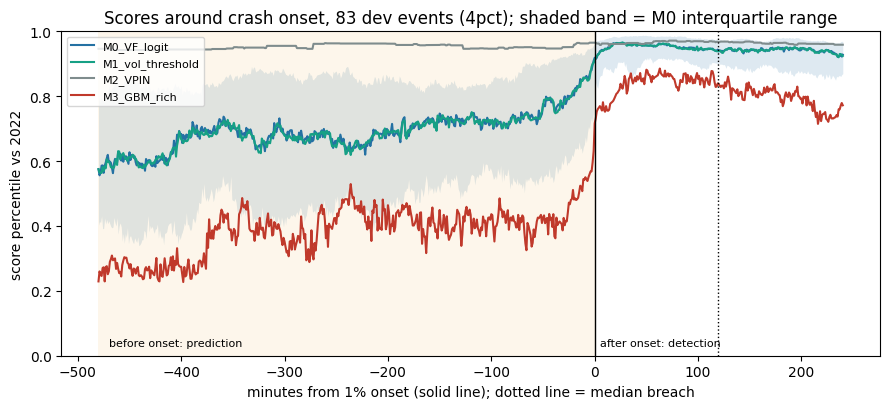

method              M0_VF_logit  M1_vol_threshold  M2_VPIN  M3_GBM_rich
minutes_from_onset                                                     
-240                      0.635             0.623    0.962        0.483
-120                      0.735             0.739    0.947        0.434
-60                       0.736             0.729    0.949        0.348
-30                       0.787             0.774    0.951        0.425
 0                        0.919             0.912    0.965        0.716
 15                       0.952             0.950    0.961        0.776
 30                       0.962             0.961    0.961        0.848
 60                       0.956             0.955    0.970        0.863


In [6]:
ev = events_between(CATS[PRIMARY_DEF], EVAL_START, EVAL_END)
onsets = ev.onset_1pct_utc.astype('int64').to_numpy(); offs = np.arange(STUDY[0], STUDY[1] + 1)
ii = ((onsets[:, None] - T[0]) // NS + offs[None, :]).astype(np.int64)
gap_med = float(((ev.breach_utc - ev.onset_1pct_utc).dt.total_seconds() / 60).median())
es_rows = []; fig, ax = plt.subplots(figsize=(9, 4.2))
colors = {'M0_VF_logit': '#2471a3', 'M1_vol_threshold': '#16a085', 'M2_VPIN': '#7f8c8d', 'M3_GBM_rich': '#c0392b'}
for mname in METHODS:
    s = SCORES[('L1_event', PRIMARY_DEF)][mname]; ref = np.sort(s[CAL & np.isfinite(s)])
    pct = np.full(len(T), np.nan); okp = np.isfinite(s); pct[okp] = np.searchsorted(ref, s[okp], 'right') / len(ref)
    P = pct[np.clip(ii, 0, len(T) - 1)]; P[(ii < 0) | (ii >= len(T))] = np.nan
    med = np.nanmedian(P, axis=0); q1, q3 = np.nanpercentile(P, [25, 75], axis=0)
    es_rows.append(pd.DataFrame(dict(method=mname, minutes_from_onset=offs, median_pct=med, q25=q1, q75=q3)))
    ax.plot(offs, med, color=colors[mname], label=mname)
    if mname == 'M0_VF_logit':
        ax.fill_between(offs, q1, q3, color=colors[mname], alpha=0.15, lw=0)
ES = pd.concat(es_rows); ES.to_csv(OUT / '4_event_study.csv', index=False)
ax.axvline(0, color='k', lw=1); ax.axvline(gap_med, color='k', lw=1, ls=':')
ax.axvspan(STUDY[0], 0, color='#f5b041', alpha=0.10, lw=0)
ax.text(STUDY[0] + 10, 0.03, 'before onset: prediction', fontsize=8); ax.text(5, 0.03, 'after onset: detection', fontsize=8)
ax.set_ylim(0, 1); ax.set_xlabel('minutes from 1% onset (solid line); dotted line = median breach'); ax.set_ylabel('score percentile vs 2022')
ax.set_title(f'Scores around crash onset, {len(ev)} dev events ({PRIMARY_DEF}); shaded band = M0 interquartile range')
ax.legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.savefig(OUT / '4_event_study.png', dpi=140); plt.show()
print(ES[ES.minutes_from_onset.isin([-240, -120, -60, -30, 0, 15, 30, 60])].pivot(index='minutes_from_onset', columns='method', values='median_pct').round(3))

## 6. Figures and summary

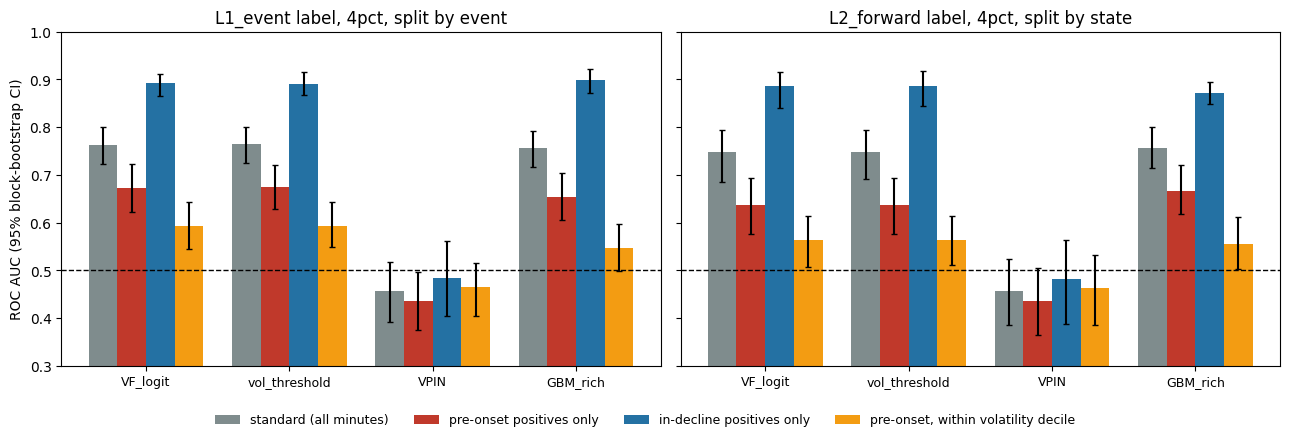

L1_event   M0_VF_logit       standard 0.763 [0.723, 0.801] | pre-onset only 0.673 [0.621, 0.722] | in-decline share of excess 0.62 | pre within regime 0.592
L1_event   M1_vol_threshold  standard 0.764 [0.725, 0.800] | pre-onset only 0.674 [0.627, 0.720] | in-decline share of excess 0.61 | pre within regime 0.594
L1_event   M2_VPIN           standard 0.456 [0.391, 0.518] | pre-onset only 0.436 [0.375, 0.497] | in-decline share of excess nan | pre within regime 0.464
L1_event   M3_GBM_rich       standard 0.755 [0.716, 0.791] | pre-onset only 0.654 [0.604, 0.704] | in-decline share of excess 0.65 | pre within regime 0.547
L2_forward M0_VF_logit       standard 0.747 [0.685, 0.793] | pre-onset only 0.637 [0.575, 0.693] | in-decline share of excess 0.69 | pre within regime 0.563
L2_forward M1_vol_threshold  standard 0.747 [0.691, 0.794] | pre-onset only 0.637 [0.577, 0.693] | in-decline share of excess 0.69 | pre within regime 0.564
L2_forward M2_VPIN           standard 0.456 [0.384, 0.523] 

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
bars = [('auc_standard', 'standard (all minutes)', '#7f8c8d'), ('auc_pre', 'pre-onset positives only', '#c0392b'),
        ('auc_in', 'in-decline positives only', '#2471a3'), ('auc_pre_within_regime', 'pre-onset, within volatility decile', '#f39c12')]
for ax, (lab, split) in zip(axes, [('L1_event', 'event'), ('L2_forward', 'state')]):
    sub = A[(A.label == lab) & (A.split == split) & (A.definition == PRIMARY_DEF)].set_index('method').reindex(METHODS)
    x = np.arange(len(METHODS))
    for j, (k, name, col) in enumerate(bars):
        v = sub[k].to_numpy(); err = np.vstack([v - sub[f'{k}_lo'].to_numpy(), sub[f'{k}_hi'].to_numpy() - v])
        ax.bar(x + (j - 1.5) * 0.2, v, width=0.2, color=col, label=name, yerr=err, capsize=2)
    ax.axhline(0.5, color='k', ls='--', lw=1); ax.set_ylim(0.3, 1.0)
    ax.set_xticks(x); ax.set_xticklabels([m.split('_', 1)[1] for m in METHODS], fontsize=9)
    ax.set_title(f'{lab} label, {PRIMARY_DEF}, split by {split}')
axes[0].set_ylabel('ROC AUC (95% block-bootstrap CI)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig(OUT / '2_auc_decomposition.png', dpi=140); plt.show()

prim = A[(A.definition == PRIMARY_DEF) & (((A.label == 'L1_event') & (A.split == 'event')) | ((A.label == 'L2_forward') & (A.split == 'state')))]
summary = dict(spec_sha256=SPEC_SHA, models_sha256=sha256_file(OUT / '18_MODELS.json'), status='exploratory, dev 2023-01..2026-04 only',
               primary=prim[['label', 'split', 'method', 'n_pos', 'share_in', 'auc_standard', 'auc_standard_lo', 'auc_standard_hi',
                             'auc_pre', 'auc_pre_lo', 'auc_pre_hi', 'auc_in', 'in_share_of_excess', 'in_share_of_excess_lo', 'in_share_of_excess_hi',
                             'auc_pre_within_regime', 'auc_pre_within_regime_lo', 'auc_pre_within_regime_hi', 'auc_calm']].to_dict('records'),
               label_composition=COMP[COMP.definition == PRIMARY_DEF].to_dict('records'),
               event_study_median_pct=ES[ES.minutes_from_onset.isin([-240, -60, -30, 0, 30, 60])].pivot(
                   index='minutes_from_onset', columns='method', values='median_pct').round(4).to_dict())
(OUT / 'INFLATION_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
for r in summary['primary']:
    print(f"{r['label']:10s} {r['method']:17s} standard {r['auc_standard']:.3f} [{r['auc_standard_lo']:.3f}, {r['auc_standard_hi']:.3f}] | "
          f"pre-onset only {r['auc_pre']:.3f} [{r['auc_pre_lo']:.3f}, {r['auc_pre_hi']:.3f}] | in-decline share of excess {r['in_share_of_excess']:.2f} | "
          f"pre within regime {r['auc_pre_within_regime']:.3f}")

## Interpretation
- The standard AUC is the number the literature reports; the pre-onset-only AUC is the Kamran-style restricted number. I measure the inflation by the gap between them and by the in-progress share of the above-chance AUC.
- A within-regime pre-onset AUC close to 0.5 means that pre-onset positives score high because they fall in high-volatility periods, not because the timing is right; this is the per-minute counterpart of the regime-matched nulls of notebooks 12, 16 and 17.
- In the event-study figure, I read a score that rises after the 1% onset line (solid) as detection and one that rises in the orange region before onset as prediction; the dotted line marks the median breach time.